In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset from Task 2
df = pd.read_csv('data_summary.tsv', sep='\t')
print("Columns available:", df.columns.tolist())

# Clean missing common names (consistent with Task 2)
if 'Organism Common Name' in df.columns:
    df['Organism Common Name'] = df['Organism Common Name'].fillna('K-12 substr. MG1655')

# Label assembly sources clearly
df['Source'] = df['Assembly Accession'].apply(
    lambda x: 'RefSeq (GCF_000005845.2)' if str(x).startswith('GCF') else 'GenBank (GCA_000005845.2)'
)

sns.set_theme(style="whitegrid", context="talk")



Columns available: ['Organism Scientific Name', 'Organism Common Name', 'Organism Qualifier', 'Taxonomy id', 'Assembly Name', 'Assembly Accession', 'Source', 'Annotation', 'Level', 'Contig N50', 'Size', 'Submission Date', 'Gene Count', 'BioProject', 'BioSample']


In [5]:
# CHART 1: Grouped Bar Chart of Annotation Feature Counts
gene_cols = [
    c for c in [
        'Annotation Count Gene Total',
        'Annotation Count Gene Protein-coding',
        'Annotation Count Gene Non-coding',
        'Annotation Count Gene Pseudogene'
    ] if c in df.columns
]

if gene_cols:
    melted_genes = df.melt(
        id_vars=['Source'], value_vars=gene_cols,
        var_name='Feature Type', value_name='Count'
    )
    melted_genes['Feature Type'] = melted_genes['Feature Type'].str.replace('Annotation Count Gene ', '')

    plt.figure(figsize=(10, 6))
    ax = sns.barplot(data=melted_genes, x='Feature Type', y='Count', hue='Source', palette='viridis')
    plt.title('E. coli K-12 MG1655: Genomic Annotation Comparison (GenBank vs. RefSeq)', pad=15)
    plt.ylabel('Gene / Feature Count')
    plt.xlabel('Genomic Feature Category')
    for container in ax.containers:
        ax.bar_label(container, fmt='%d', padding=3, fontsize=10)
    plt.tight_layout()
    plt.savefig('1_Annotation_Comparison.png', dpi=300)
    plt.show()


In [6]:
# CHART 2: Gene Biotype Composition (RefSeq Record)
refseq_row = df[df['Source'].str.contains('RefSeq')].iloc[0]
biotype_cols = [c for c in gene_cols if 'Total' not in c]

if biotype_cols:
    counts = [refseq_row[c] for c in biotype_cols]
    labels = [c.replace('Annotation Count Gene ', '') for c in biotype_cols]

    plt.figure(figsize=(8, 6))
    colors = sns.color_palette('Set2', len(labels))
    plt.pie(
        counts, labels=labels, autopct='%1.1f%%', startangle=140,
        colors=colors, wedgeprops={'edgecolor': 'white', 'linewidth': 2}
    )
    plt.title('Genomic Feature Composition of E. coli K-12 MG1655 (RefSeq)', pad=15)
    plt.tight_layout()
    plt.savefig('2_Gene_Composition_Pie.png', dpi=300)
    plt.show()

In [7]:
# CHART 3: Assembly Contiguity & Size Metrics
metrics = [
    c for c in [
        'Assembly Stats Total Sequence Length',
        'Assembly Stats Ungapped Length',
        'Assembly Stats Contig N50'
    ] if c in df.columns
]

if metrics:
    melted_metrics = df.melt(
        id_vars=['Source'], value_vars=metrics,
        var_name='Metric', value_name='Base Pairs'
    )
    melted_metrics['Metric'] = melted_metrics['Metric'].str.replace('Assembly Stats ', '')
    melted_metrics['Megabases (Mb)'] = melted_metrics['Base Pairs'] / 1e6

    plt.figure(figsize=(10, 5))
    ax2 = sns.barplot(data=melted_metrics, x='Metric', y='Megabases (Mb)', hue='Source', palette='mako')
    plt.title('Assembly Completeness & Contiguity Metrics (4.64 Mb Chromosome)', pad=15)
    plt.ylabel('Length (Megabases - Mb)')
    plt.xlabel('Assembly Metric')
    plt.ylim(0, 5.5)
    for container in ax2.containers:
        ax2.bar_label(container, fmt='%.2f Mb', padding=3, fontsize=10)
    plt.tight_layout()
    plt.savefig('3_Assembly_Contiguity.png', dpi=300)
    plt.show()

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 1. Load and clean dataset
df = pd.read_csv('data_summary.tsv', sep='\t')
df['Organism Common Name'] = df['Organism Common Name'].fillna('K-12 substr. MG1655')
df['Database'] = df['Source'] + ' (' + df['Assembly Accession'] + ')'
sns.set_theme(style="whitegrid", context="talk")

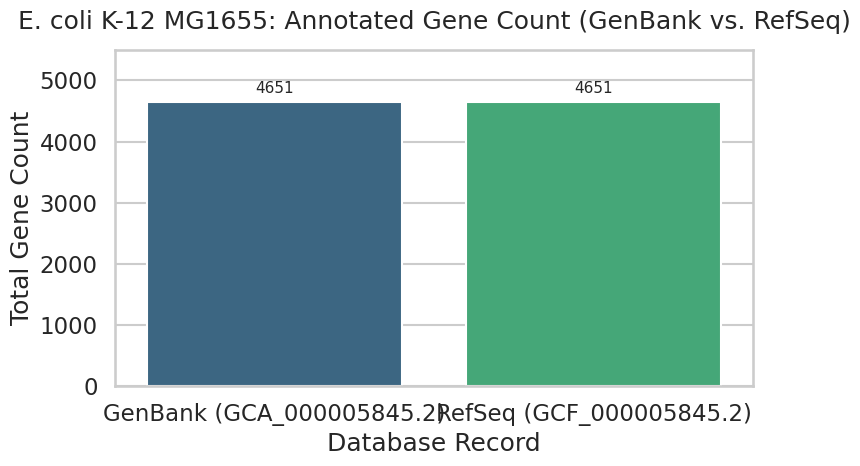

In [9]:
# CHART 1: Total Annotated Gene Count Comparison
plt.figure(figsize=(8, 5))
ax1 = sns.barplot(data=df, x='Database', y='Gene Count', hue='Database', palette='viridis', legend=False)
plt.title('E. coli K-12 MG1655: Annotated Gene Count (GenBank vs. RefSeq)', pad=15)
plt.ylabel('Total Gene Count')
plt.xlabel('Database Record')
plt.ylim(0, 5500)
for container in ax1.containers:
    ax1.bar_label(container, fmt='%d', padding=4, fontsize=11)
plt.tight_layout()
plt.savefig('1_Gene_Count_Comparison.png', dpi=300)
plt.show()

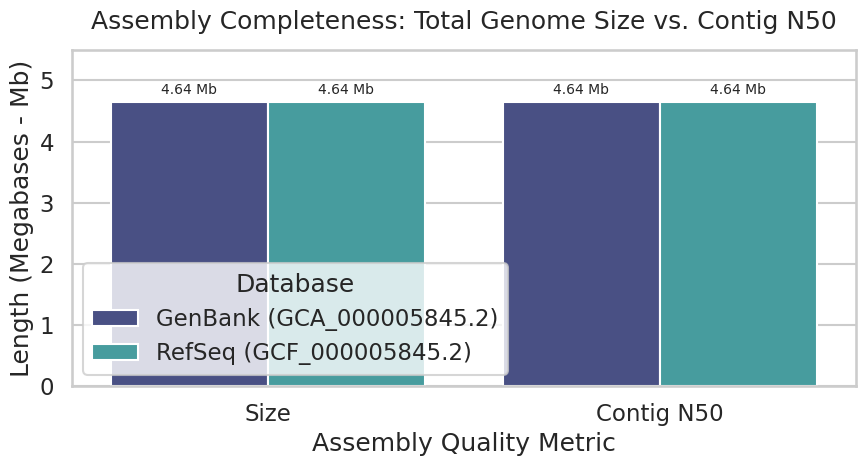

In [10]:
# CHART 2: Assembly Size vs. Contig N50 (Contiguity Proof)
melted_size = df.melt(
    id_vars=['Database'],
    value_vars=['Size', 'Contig N50'],
    var_name='Metric',
    value_name='Base Pairs'
)
melted_size['Megabases (Mb)'] = melted_size['Base Pairs'] / 1e6

plt.figure(figsize=(9, 5))
ax2 = sns.barplot(data=melted_size, x='Metric', y='Megabases (Mb)', hue='Database', palette='mako')
plt.title('Assembly Completeness: Total Genome Size vs. Contig N50', pad=15)
plt.ylabel('Length (Megabases - Mb)')
plt.xlabel('Assembly Quality Metric')
plt.ylim(0, 5.5)
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.2f Mb', padding=4, fontsize=10)
plt.tight_layout()
plt.savefig('2_Assembly_Contiguity.png', dpi=300)
plt.show()

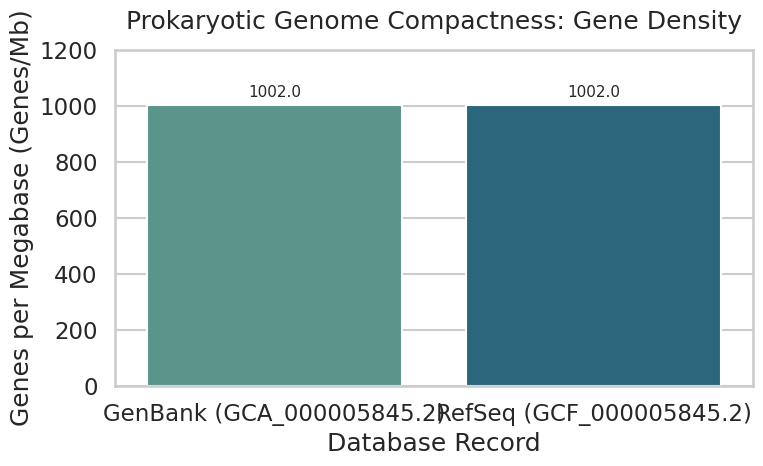

In [11]:
# CHART 3: Gene Density Comparison (Genes per Megabase)
df['Gene Density (Genes/Mb)'] = df['Gene Count'] / (df['Size'] / 1e6)
plt.figure(figsize=(8, 5))
ax3 = sns.barplot(data=df, x='Database', y='Gene Density (Genes/Mb)', hue='Database', palette='crest', legend=False)
plt.title('Prokaryotic Genome Compactness: Gene Density', pad=15)
plt.ylabel('Genes per Megabase (Genes/Mb)')
plt.xlabel('Database Record')
plt.ylim(0, 1200)
for container in ax3.containers:
    ax3.bar_label(container, fmt='%.1f', padding=4, fontsize=11)
plt.tight_layout()
plt.savefig('3_Gene_Density.png', dpi=300)
plt.show()